<a href="https://colab.research.google.com/github/nandah4/PCVK_Ganjil_26/blob/main/Week7.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# MODUL 6 – Filter Spasial Low Pass, High Pass, Point Detection, Line Detection, Edge Detection


## Tujuan
- Memahami konsep filter spasial
- Mengetahui beberapa jenis filter spasial
- Membuat filter dengan kernel dan menghitung konvolusi sendiri (tanpa fungsi konvolusi OpenCV)

## Konsep singkat
- **Filter spasial** = mengubah nilai piksel berdasarkan piksel tetangganya.
- **Kernel** = matriks kecil (mis. 3x3) berisi bobot.
- **Konvolusi** = kernel digeser ke seluruh citra; di tiap posisi, kalikan bobot kernel dengan piksel di bawahnya lalu jumlahkan. Hasilnya menjadi 1 piksel baru.
- **Low Pass Filter** = menekan frekuensi tinggi (blur/halus).
- **High Pass Filter** = menekan frekuensi rendah (tepi/detail makin jelas).

In [ ]:
# Import Library & Mount Google Drive

from google.colab import drive
drive.mount('/content/drive')

import numpy as np
import matplotlib.pyplot as plt
import cv2 as cv
import math
from google.colab.patches import cv2_imshow
from PIL import Image as im

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


## Helper Function
Fungsi dari modul untuk menampilkan beberapa gambar dalam 1 baris.
- Jika gambar 2 dimensi → dianggap grayscale.
- Jika 3 dimensi → gambar berwarna. OpenCV membaca warna dengan urutan **BGR**, sedangkan matplotlib memakai **RGB**, jadi perlu dikonversi dulu.

Fungsi `u8` mengubah hasil konvolusi ke rentang 0–255. Hasil konvolusi bisa negatif atau lebih dari 255, padahal gambar hanya boleh 0–255. Dengan `mutlak=True`, nilai negatif dijadikan positif (dipakai untuk deteksi tepi).

In [ ]:
def show_side_by_side(images, titles, figsize=(15,5)):
    plt.figure(figsize=figsize)
    for i, (img, title) in enumerate(zip(images, titles)):
        plt.subplot(1, len(images), i+1)
        if len(img.shape) == 2:  # grayscale
            plt.imshow(img, cmap="gray")
        else:  # color
            plt.imshow(cv.cvtColor(img, cv.COLOR_BGR2RGB))
        plt.title(title)
        plt.axis("off")
    plt.show()

def u8(x, mutlak=False):
    if mutlak:
        x = np.abs(x)
    return np.clip(x, 0, 255).astype(np.uint8)

## Konvolusi tanpa Library
Fungsi `convolution2d` memiliki parameter:
1. `image`   : citra masukan
2. `kernel`  : matriks kernel untuk memfilter citra
3. `stride`  : besar pergeseran kernel tiap konvolusi
4. `padding` : jumlah piksel (bernilai 0) yang ditambahkan di sekeliling citra

### Cara kerja per langkah
1. Ubah citra & kernel ke tipe `float` agar hasil negatif/desimal tidak terpotong.
2. **Padding**: tambahkan bingkai 0 di sekeliling citra. Ini menyelesaikan masalah border ("efek menggantung"), yaitu solusi ke-3 di modul (piksel di luar citra dianggap 0).
3. Hitung ukuran output:  `(N + 2*padding - K) / stride + 1`
4. Geser kernel dari kiri-atas ke kanan-bawah. Di tiap posisi: ambil potongan citra seukuran kernel, kalikan elemen demi elemen dengan kernel, lalu jumlahkan (`np.sum`).
5. Simpan hasil jumlahan ke posisi output.

Catatan: padding = `kernel//2` (kernel 3x3 → padding 1) membuat ukuran hasil sama dengan citra asli.

In [ ]:
def convolution2d(image, kernel, stride=1, padding=0):
    image = np.array(image, dtype=np.float64)
    kernel = np.array(kernel, dtype=np.float64)

    # padding dengan nilai 0 di sekeliling citra
    if padding > 0:
        image = np.pad(image, padding, mode="constant", constant_values=0)

    H, W = image.shape
    kh, kw = kernel.shape

    # ukuran output
    out_h = (H - kh) // stride + 1
    out_w = (W - kw) // stride + 1
    output = np.zeros((out_h, out_w))

    # geser kernel ke seluruh citra
    for y in range(out_h):
        for x in range(out_w):
            region = image[y*stride : y*stride+kh, x*stride : x*stride+kw]
            output[y, x] = np.sum(region * kernel)

    return output

## Uji fungsi
Citra 5x5 dengan kernel Laplacian 3x3. Perhitungan manual di modul untuk piksel pertama:
`(0x4)+(-1x4)+(0x3)+(-1x6)+(4x6)+(-1x5)+(0x5)+(-1x6)+(0x6) = 3`

Dengan padding 0, ukuran hasil = (5-3)/1+1 = 3, jadi 3x3. Hasil yang benar adalah `[[3,0,2],[0,2,6],[6,0,2]]`.

In [ ]:
f = np.array([[4, 4, 3, 5, 4],
              [6, 6, 5, 5, 2],
              [5, 6, 6, 6, 2],
              [6, 7, 5, 5, 3],
              [3, 5, 2, 4, 4]])

k = np.array([[ 0, -1,  0],
              [-1,  4, -1],
              [ 0, -1,  0]])

print(convolution2d(f, k, 1, 0))

[[3. 0. 2.]
 [0. 2. 6.]
 [6. 0. 2.]]


## Langkah d – Load citra dan ubah menjadi keabuan
- `cv.imread` : membaca citra dari Drive (hasilnya BGR).
- `cv.cvtColor(..., COLOR_BGR2GRAY)` : mengubah menjadi grayscale (1 kanal, nilai 0–255) agar konvolusi lebih sederhana.

Sesuaikan path dengan lokasi file Anda di Drive.

(1600, 1067)


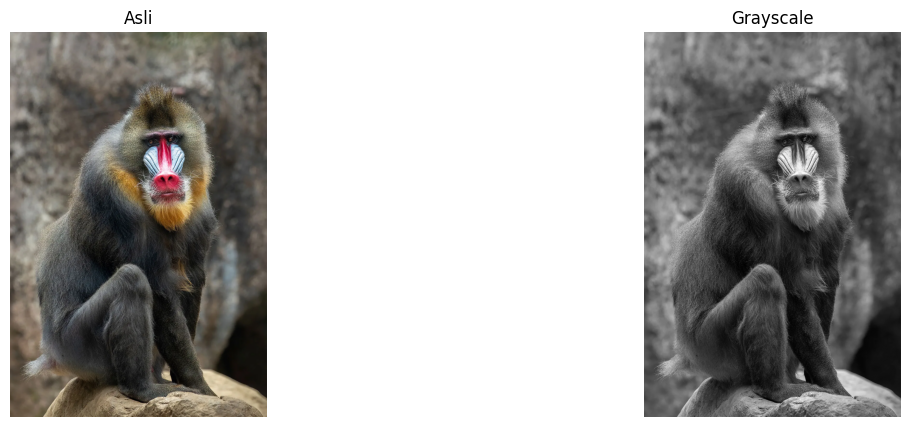

In [ ]:
img = cv.imread('/content/drive/MyDrive/Polinema/Semester 5/PCVK/Pertemuan 7/Mandrill.webp')
img_gray = cv.cvtColor(img, cv.COLOR_BGR2GRAY)
print(img_gray.shape)
show_side_by_side([img, img_gray], ["Asli", "Grayscale"])

## Langkah e – Tentukan kernel
Contoh kernel **sharpening**: pusat bernilai besar (+5), tetangga negatif, sehingga piksel pusat diperkuat terhadap tetangganya. Jumlah semua elemen = 1, jadi kecerahan rata-rata tetap.

In [ ]:
#image sharpen
kernel_sharpen = np.array([[0,-1,0],
                           [-1,5,-1],
                           [0,-1,0]])

## Langkah f – Panggil fungsi konvolusi dan tampilkan hasil
Modul memakai `padding=2`. Dengan kernel 3x3, hasilnya menjadi 2 piksel lebih besar dari citra asli (514x514). Agar ukurannya sama dengan citra asli, pakai `padding=1`. Kita tampilkan keduanya untuk perbandingan.

(1600, 1067) (1602, 1069) (1600, 1067)


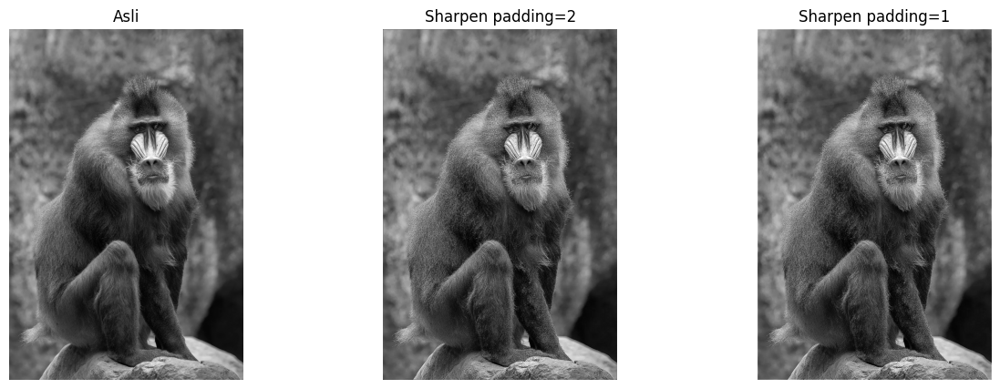

In [ ]:
hasil_p2 = convolution2d(img_gray, kernel_sharpen, 1, 2)   # sesuai modul
hasil_p1 = convolution2d(img_gray, kernel_sharpen, 1, 1)   # ukuran sama dengan asli
print(img_gray.shape, hasil_p2.shape, hasil_p1.shape)

show_side_by_side([img_gray, u8(hasil_p2), u8(hasil_p1)],
                  ["Asli", "Sharpen padding=2", "Sharpen padding=1"])

## Fungsi `filter_citra`
Agar ringkas, dibuat fungsi pembungkus yang otomatis memakai `padding = ukuran kernel // 2` sehingga ukuran hasil sama dengan citra asli. Setelah itu hasil diubah ke 0–255 dengan `u8`.

In [ ]:
def filter_citra(gray, kernel, mutlak=False):
    kernel = np.array(kernel, dtype=np.float64)
    hasil = convolution2d(gray, kernel, 1, kernel.shape[0]//2)
    return u8(hasil, mutlak)

## 1. Average Filter, Low Pass Filter, High Pass Filter
- **Average 3x3** : rata-rata 9 piksel → blur. Dibagi 9 agar total bobot = 1 (kecerahan tetap).
- **Low Pass** : mirip average, tetapi piksel pusat diberi bobot lebih besar (4) → blur lebih lembut. Dibagi 12 agar total bobot = 1.
- **High Pass** : jumlah elemen kernel = 0, jadi area yang rata menjadi hitam dan hanya perubahan tajam (tepi/detail) yang tersisa. Nilai negatif diubah ke mutlak agar tampak.

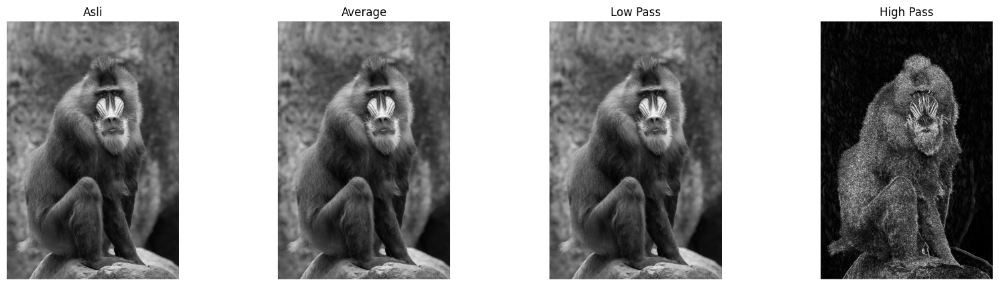

In [ ]:
kernel_average = np.ones((3,3)) / 9

kernel_lowpass = np.array([[1,1,1],
                           [1,4,1],
                           [1,1,1]]) / 12

kernel_highpass = np.array([[-1,0,1],
                            [-1,0,3],
                            [-3,0,1]])

average  = filter_citra(img_gray, kernel_average)
lowpass  = filter_citra(img_gray, kernel_lowpass)
highpass = filter_citra(img_gray, kernel_highpass, mutlak=True)

show_side_by_side([img_gray, average, lowpass, highpass],
                  ["Asli", "Average", "Low Pass", "High Pass"], figsize=(20,5))

## 2. Sharpen dan Emboss
- **Sharpen** : memperjelas tepi, citra tampak lebih tajam.
- **Emboss** : efek timbul/relief. Arah penguatan dari elemen negatif (kiri-atas) ke positif (kanan-bawah).

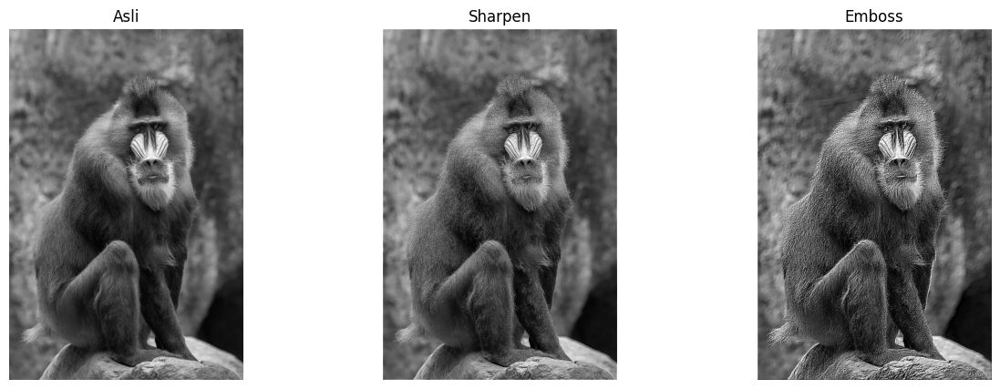

In [ ]:
kernel_emboss = np.array([[-2,-1,0],
                          [-1, 1,1],
                          [ 0, 1,2]])

sharpen = filter_citra(img_gray, kernel_sharpen)
emboss  = filter_citra(img_gray, kernel_emboss)

show_side_by_side([img_gray, sharpen, emboss],
                  ["Asli", "Sharpen", "Emboss"])

## 3. Left Sobel, "Canny" , dan Gaussian Blur 21x21
- **Left Sobel** : mendeteksi tepi vertikal (perubahan intensitas kiri-kanan).
- **Kernel "Canny" di modul** (`8` di tengah, `-1` di sekeliling) sebenarnya kernel Laplacian 8-tetangga. Canny yang asli ada di Percobaan 1 (`cv.Canny`).
- **Gaussian 21x21** : blur sangat kuat. Kernel dibuat dari kode modul:
  1. `sigma = sqrt(kernel_size)`
  2. `getGaussianKernel` menghasilkan kernel 1D (21x1)
  3. `g @ g.T` mengubahnya menjadi kernel 2D (21x21)


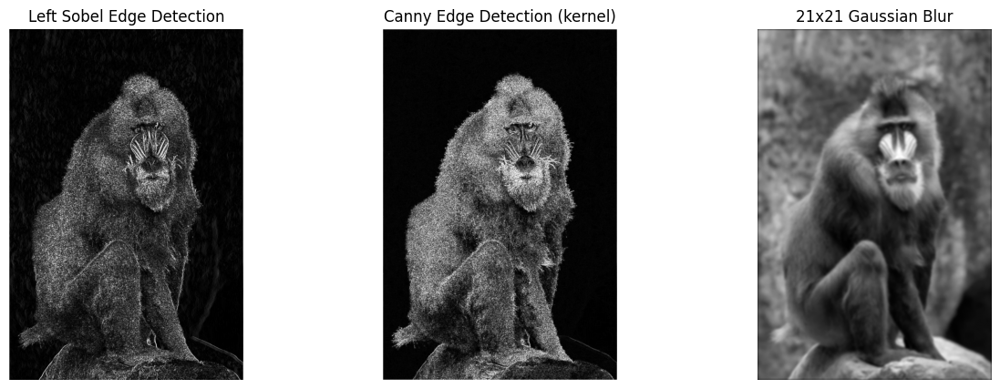

In [ ]:
kernel_sobel_left = np.array([[1,0,-1],
                              [2,0,-2],
                              [1,0,-1]])

kernel_canny = np.array([[-1,-1,-1],
                         [-1, 8,-1],
                         [-1,-1,-1]])

kernel_size = 21
sigma = math.sqrt(kernel_size)
gaussian_kernel = cv.getGaussianKernel(kernel_size, sigma)
gauss_kernel = gaussian_kernel @ gaussian_kernel.transpose()

sobel_left = filter_citra(img_gray, kernel_sobel_left, mutlak=True)
canny_k    = filter_citra(img_gray, kernel_canny, mutlak=True)
gauss21    = filter_citra(img_gray, gauss_kernel)

show_side_by_side([sobel_left, canny_k, gauss21],
                  ["Left Sobel Edge Detection", "Canny Edge Detection (kernel)", "21x21 Gaussian Blur"])

## 4. Point Detection
Kernel `[[1,1,1],[1,-8,1],[1,1,1]]` (jumlah = 0) hanya bereaksi pada **titik terisolasi** yang nilainya jauh berbeda dari 8 tetangganya. Area rata menghasilkan 0.

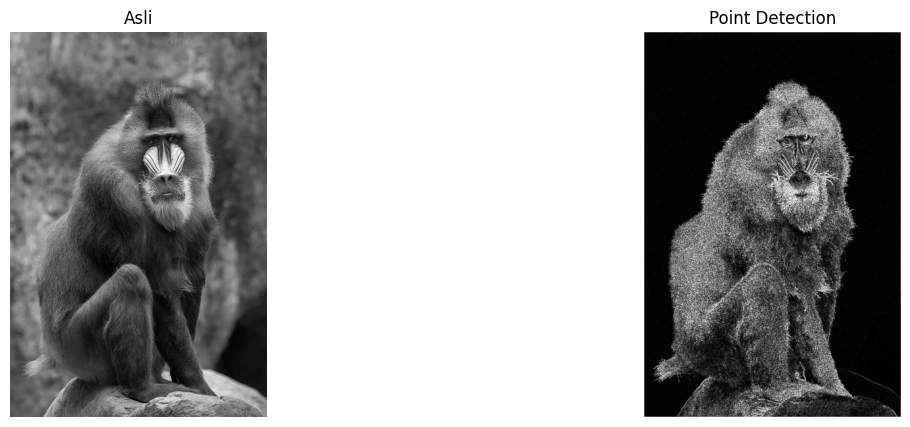

In [ ]:
kernel_point = np.array([[1, 1, 1],
                         [1,-8, 1],
                         [1, 1, 1]])

point = filter_citra(img_gray, kernel_point, mutlak=True)
show_side_by_side([img_gray, point], ["Asli", "Point Detection"])

## 5. Line Detection
Tiap kernel mendeteksi garis tipis pada satu arah: nilai `2` pada arah garis, `-1` di sekitarnya. Ada 4 arah: Horizontal, +45°, Vertikal, -45°.

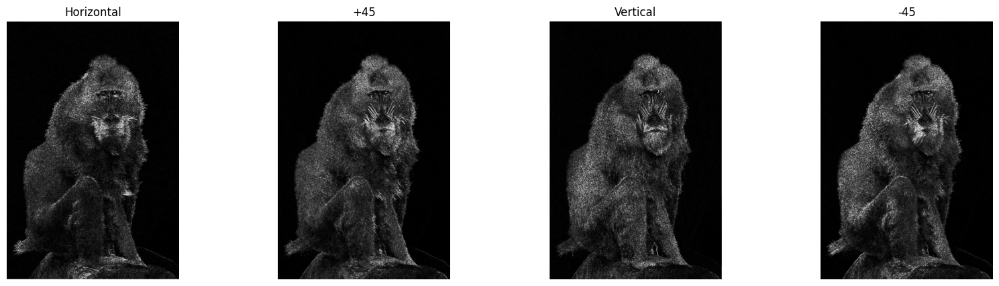

In [ ]:
k_horizontal = np.array([[-1,-1,-1],
                         [ 2, 2, 2],
                         [-1,-1,-1]])
k_plus45 = np.array([[ 2,-1,-1],
                     [-1, 2,-1],
                     [-1,-1, 2]])
k_vertical = np.array([[-1, 2,-1],
                       [-1, 2,-1],
                       [-1, 2,-1]])
k_minus45 = np.array([[-1,-1, 2],
                      [-1, 2,-1],
                      [ 2,-1,-1]])

line_h  = filter_citra(img_gray, k_horizontal, mutlak=True)
line_p  = filter_citra(img_gray, k_plus45, mutlak=True)
line_v  = filter_citra(img_gray, k_vertical, mutlak=True)
line_m  = filter_citra(img_gray, k_minus45, mutlak=True)

show_side_by_side([line_h, line_p, line_v, line_m],
                  ["Horizontal", "+45", "Vertical", "-45"], figsize=(20,5))

## 6. Edge Detection: Roberts, Prewitt, Sobel
Ketiganya mengukur **gradien** (perubahan intensitas). Tiap operator punya 2 kernel: satu untuk arah x dan satu untuk arah y. Hasil akhir = `|Gx| + |Gy|`.

- **Roberts** : kernel 2x2 (paling sederhana) → padding 0.
- **Prewitt** : kernel 3x3 dengan bobot rata.
- **Sobel** : kernel 3x3, bobot 2 di tengah sehingga lebih tahan noise.

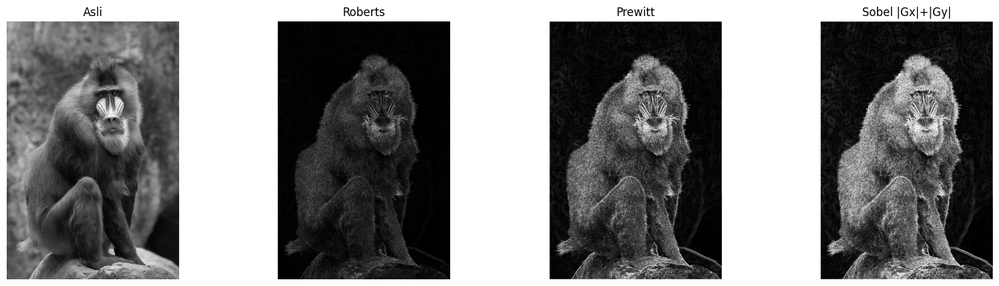

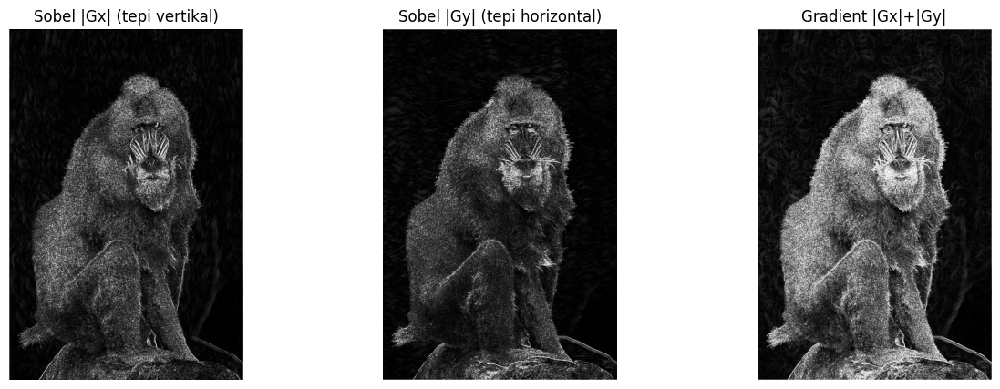

In [ ]:
# Roberts (2x2)
roberts_1 = np.array([[-1,0],[0,1]])
roberts_2 = np.array([[0,-1],[1,0]])
r1 = convolution2d(img_gray, roberts_1, 1, 0)
r2 = convolution2d(img_gray, roberts_2, 1, 0)
roberts = u8(np.abs(r1) + np.abs(r2))

# Prewitt (3x3)
prewitt_y = np.array([[-1,-1,-1],[0,0,0],[1,1,1]])
prewitt_x = np.array([[-1,0,1],[-1,0,1],[-1,0,1]])
prewitt = u8(np.abs(convolution2d(img_gray, prewitt_x, 1, 1)) +
             np.abs(convolution2d(img_gray, prewitt_y, 1, 1)))

# Sobel (3x3)
sobel_y = np.array([[-1,-2,-1],[0,0,0],[1,2,1]])
sobel_x = np.array([[-1,0,1],[-2,0,2],[-1,0,1]])
gx = convolution2d(img_gray, sobel_x, 1, 1)
gy = convolution2d(img_gray, sobel_y, 1, 1)
sobel = u8(np.abs(gx) + np.abs(gy))

show_side_by_side([img_gray, roberts, prewitt, sobel],
                  ["Asli", "Roberts", "Prewitt", "Sobel |Gx|+|Gy|"], figsize=(20,5))
show_side_by_side([u8(gx, True), u8(gy, True), sobel],
                  ["Sobel |Gx| (tepi vertikal)", "Sobel |Gy| (tepi horizontal)", "Gradient |Gx|+|Gy|"])

# Filter Library dan Filter Modern

## Percobaan 1 – Gaussian, Sharpen, dan Canny dengan OpenCV
- `cv.GaussianBlur(img, (7,7), 1)` : blur Gaussian, kernel 7x7, sigma 1.
- `cv.filter2D(img, -1, kernel)` : konvolusi dengan kernel buatan sendiri (versi library dari `convolution2d`). `-1` berarti tipe data output sama dengan input.
- `cv.Canny(gray, 100, 200)` : deteksi tepi Canny; 100 & 200 adalah ambang bawah dan atas.

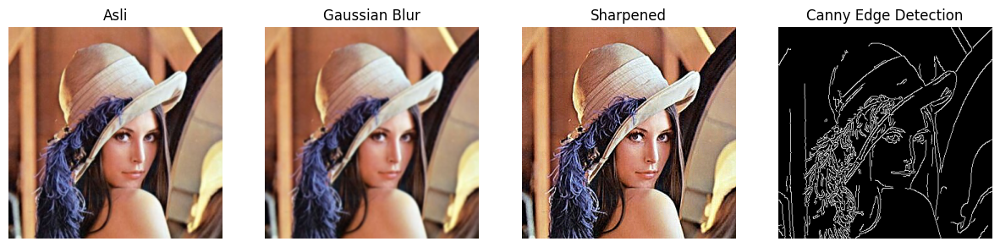

In [ ]:
img = cv.imread("/content/drive/MyDrive/Polinema/Semester 5/PCVK/Images/lena.jpg")
img_gray = cv.cvtColor(img, cv.COLOR_BGR2GRAY)

blur = cv.GaussianBlur(img, (7,7), 1)
edges = cv.Canny(cv.cvtColor(img, cv.COLOR_BGR2GRAY), 100, 200)
sharpen_kernel = np.array([[0,-1,0],[-1,5,-1],[0,-1,0]])
sharpened = cv.filter2D(img, -1, sharpen_kernel)
show_side_by_side([img, blur, sharpened, edges],
                  ["Asli", "Gaussian Blur", "Sharpened", "Canny Edge Detection"])

## Percobaan 2 – Bilateral Filter dan Edge Preserving Filter
- **Bilateral filter** : penyaringan non-linear yang menghaluskan citra **sambil menjaga ketajaman tepi**. Berbeda dengan Gaussian yang hanya melihat jarak antar piksel, bilateral juga melihat **perbedaan warna**: piksel yang dekat dan warnanya mirip diberi bobot besar, piksel yang warnanya kontras (di seberang tepi) diberi bobot kecil. Hasilnya area datar halus tetapi garis batas tetap tajam. Kekurangannya cukup lambat.
- **Edge Preserving Filter** : alternatif Guided Filter bawaan OpenCV, lebih halus dan efisien.

Parameter bilateral: `d` = diameter tetangga, `sigmaColor` = toleransi beda warna, `sigmaSpace` = jangkauan jarak.

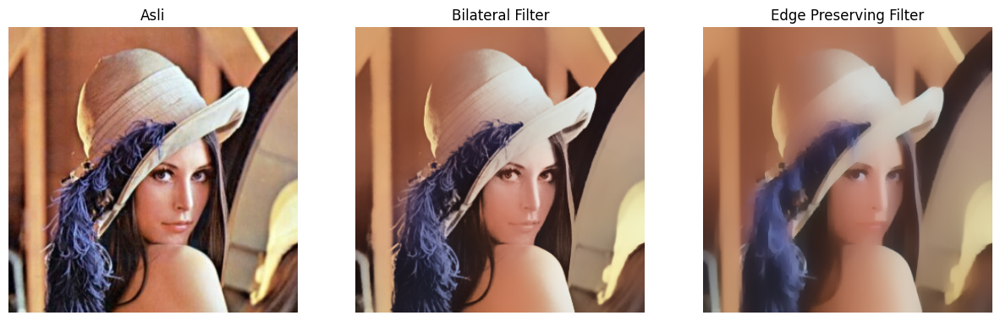

In [ ]:
# Bilateral Filter (edge-preserving)
bilateral = cv.bilateralFilter(img, 50, 100, 100)

# Edge Preserving Filter (alternatif Guided Filter)
edge_preserve = cv.edgePreservingFilter(img, flags=1, sigma_s=100, sigma_r=0.9)

show_side_by_side([img, bilateral, edge_preserve],
                  ["Asli", "Bilateral Filter", "Edge Preserving Filter"])

## Percobaan 3 – Filtering pada CNN (Feature Map)
Di sini dibuat CNN 1 layer: `Conv2d(1, 4, kernel_size=3, stride=1, padding=1)` → 1 kanal masuk, 4 filter 3x3 → 4 *feature map*. Bobot awalnya **acak** (belum dilatih).


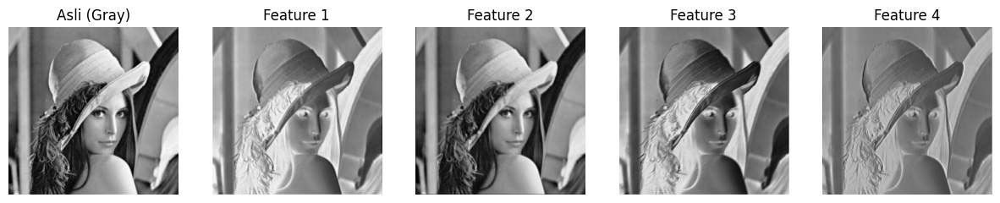

In [ ]:
import torch
import torch.nn as nn

class SimpleCNN(nn.Module):
    def __init__(self):
        super(SimpleCNN, self).__init__()
        self.conv1 = nn.Conv2d(1, 4, kernel_size=3, stride=1, padding=1)

    def forward(self, x):
        return self.conv1(x)

model = SimpleCNN()

# Ubah gambar ke tensor
img_tensor = torch.tensor(img_gray, dtype=torch.float32).unsqueeze(0).unsqueeze(0) / 255.0

# Hasil CNN
with torch.no_grad():
    features = model(img_tensor)

# Visualisasi feature maps
feature_maps = [features[0,i].numpy() for i in range(features.shape[1])]
show_side_by_side([img_gray] + feature_maps, ["Asli (Gray)"] + [f"Feature {i+1}" for i in range(len(feature_maps))])

## Percobaan 4 – Efek Beauty dan Vintage
Kombinasi filter tradisional.

**Beauty Filter**
1. *Bilateral filter* → menghaluskan kulit, tepi (mata/bibir) tetap tajam.
2. *Unsharp masking* → mempertajam detail: `hasil = 1.5 x smooth - 0.5 x blur`.
3. *Brightness & contrast* → `hasil = alpha x piksel + beta`.

**Old/Vintage Filter**
1. *Sepia* → mengalikan warna dengan matriks 3x3 (`cv.transform`).
2. *Vignette* → pinggiran gelap, dibuat dari kernel Gaussian 2D sebagai mask lalu dikalikan ke tiap kanal.
3. *Noise/Grain* → menambah derau acak agar tampak seperti foto lawas.

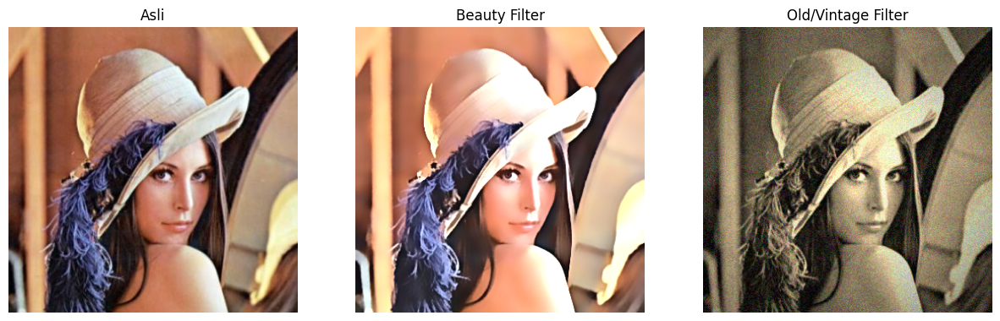

In [ ]:
# 1. Beauty Filter

# Step 1: Smoothing kulit dengan bilateral filter
smooth = cv.bilateralFilter(img, d=15, sigmaColor=75, sigmaSpace=75)

# Step 2: Unsharp masking (pertajam mata/bibir)
gaussian = cv.GaussianBlur(smooth, (0,0), 3)
sharpened = cv.addWeighted(smooth, 1.5, gaussian, -0.5, 0)

# Step 3: Brightness & contrast
alpha = 1.2  # contrast
beta = 15    # brightness
beauty = cv.convertScaleAbs(sharpened, alpha=alpha, beta=beta)

# 2. Old/Vintage Filter

# Step 1: Sepia tone
sepia_kernel = np.array([[0.272, 0.534, 0.131],
                         [0.349, 0.686, 0.168],
                         [0.393, 0.769, 0.189]])
sepia = cv.transform(img, sepia_kernel)
sepia = np.clip(sepia, 0, 255).astype(np.uint8)

# Step 2: Vignette
rows, cols = img.shape[:2]
kernel_x = cv.getGaussianKernel(cols, cols*0.6)
kernel_y = cv.getGaussianKernel(rows, rows*0.6)
kernel = kernel_y * kernel_x.T
mask = kernel / kernel.max()
vignette = np.copy(sepia)
for i in range(3):
    vignette[:,:,i] = vignette[:,:,i] * mask

# Step 3: Noise/Grain
noise = np.random.normal(0, 15, vignette.shape).astype(np.int16)
old_img = np.clip(vignette.astype(np.int16) + noise, 0, 255).astype(np.uint8)

show_side_by_side([img, beauty, old_img], ["Asli", "Beauty Filter", "Old/Vintage Filter"])

## Percobaan 5 – Filter Anime / Cartoon
Efek kartun = **warna rata + garis tepi tegas**.
1. Gray → `medianBlur(7)` untuk membuang noise kecil agar garis tidak berantakan.
2. `adaptiveThreshold` → deteksi garis tepi dengan threshold lokal (garis = hitam, lainnya = putih).
3. `bilateralFilter` → meratakan warna tetapi menjaga tepi.
4. `bitwise_and` dengan mask garis → warna hanya muncul di area putih mask, garis menjadi hitam.

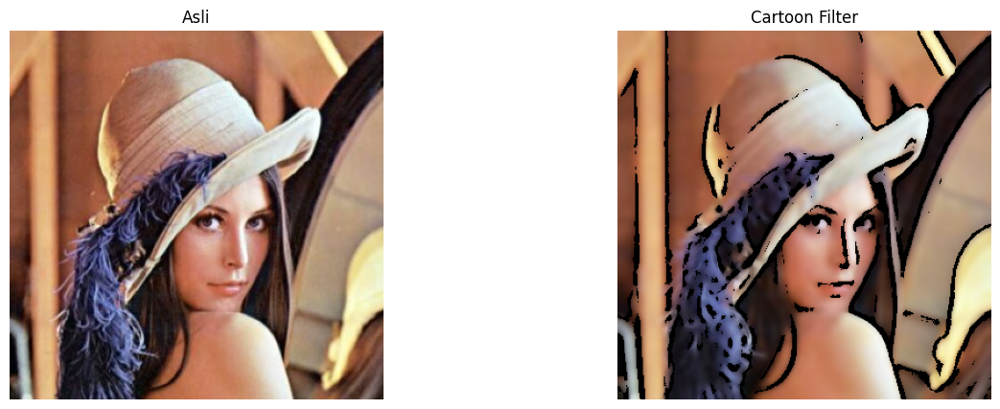

In [ ]:
#Filter Anime / Cartoon
# Step 1: Edge detection (pakai median blur dulu agar gambar menjadi lebih halus)
gray = cv.cvtColor(img, cv.COLOR_BGR2GRAY)
gray_blur = cv.medianBlur(gray, 7)
edges = cv.adaptiveThreshold(gray_blur, 255,
                             cv.ADAPTIVE_THRESH_MEAN_C,
                             cv.THRESH_BINARY, 9, 9)

# Step 2: Bilateral filter untuk smoothing warna
color = cv.bilateralFilter(img, d=9, sigmaColor=200, sigmaSpace=200)

# Step 3: Gabungkan (cartoonize)
cartoon = cv.bitwise_and(color, color, mask=edges)

# Tampilkan
show_side_by_side([img, cartoon], ["Asli", "Cartoon Filter"])

## Percobaan 6 – Filter Malam
Memakai foto pemandangan (`djawatan.jpg`).
1. **Gelapkan** : `alpha=0.6` (kontras turun), `beta=-40` (kecerahan turun).
2. **Tint biru** : campur dengan layer warna konstan (`addWeighted` 0.8 : 0.2). Ingat urutan OpenCV adalah **BGR**.
3. **Glow** : blur dengan kernel rata-rata 15x15 (`np.ones/225`) memakai `filter2D`, lalu digabung dengan citra malam agar area terang tampak berpendar.

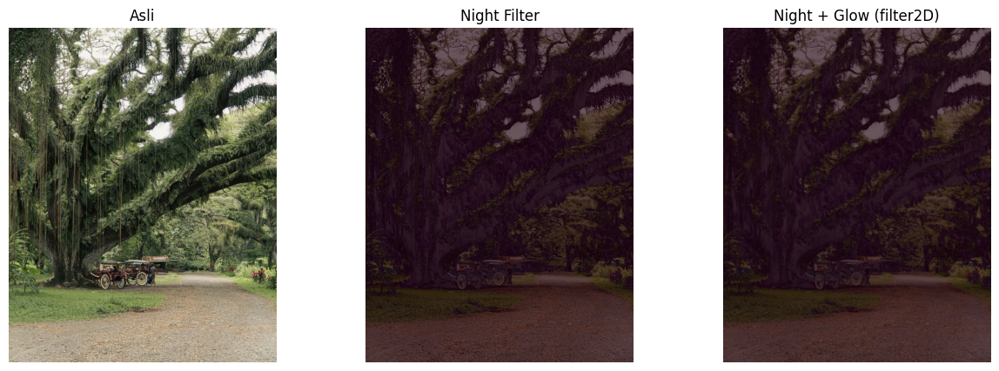

In [ ]:
#Night Filter
img = cv.imread("/content/drive/MyDrive/Polinema/Semester 5/PCVK/Pertemuan 7/djawatan.jpg")
img_gray = cv.cvtColor(img, cv.COLOR_BGR2GRAY)

# Step 1: Gelapkan (contrast turun, brightness negatif)
night = cv.convertScaleAbs(img, alpha=0.6, beta=-40)

# Step 2: Tambah bias biru
blue_tint = np.full_like(night, (50, 0, 100))  # BGR
night = cv.addWeighted(night, 0.8, blue_tint, 0.2, 0)

# Step 3: Efek glow di area terang dengan filter2D (blur kernel)
kernel = np.ones((15,15), np.float32) / 225
glow = cv.filter2D(night, -1, kernel)

# Kombinasikan asli + glow
night_glow = cv.addWeighted(night, 0.7, glow, 0.3, 0)

show_side_by_side([img, night, night_glow],
                  ["Asli", "Night Filter", "Night + Glow (filter2D)"])

## Percobaan 7 – Filter Pagi dan Kabut
1. **Soft & cerah** : `alpha=0.9` (kontras sedikit turun), `beta=20` (lebih terang).
2. **Warm tone** : campur dengan warna oranye `(40,70,120)` (BGR) sebesar 20%.
3. **Haze (kabut tipis)** : blur dengan kernel Gaussian 3x3 (`getGaussianKernel` lalu `@ kernel.T` jadi 2D), kemudian campur dengan layer putih 30% sehingga kontras turun dan tampak berkabut.

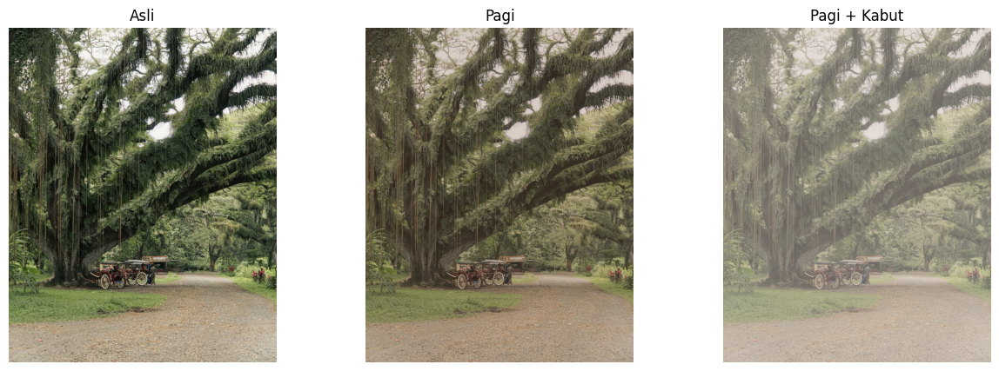

In [ ]:
#Filter Suasana pagi dan Kabut
# Step 1: Kurangi kontras & cerahkan
alpha = 0.9   # contrast
beta = 20     # brightness
soft = cv.convertScaleAbs(img, alpha=alpha, beta=beta)

# Step 2: Tambahkan warm tone (kemerahan / oranye)
warm_tint = np.full_like(soft, (40, 70, 120))  # BGR
pagi = cv.addWeighted(soft, 0.8, warm_tint, 0.2, 0)

# Step 3: Tambahkan haze (kabut tipis) dengan filter2D
# Kernel blur Gaussian-like untuk menciptakan efek kabut
kernel = cv.getGaussianKernel(3, 3)
kernel = kernel @ kernel.T  # jadikan 2D kernel
kabut = cv.filter2D(pagi, -1, kernel)

# tambah layer putih untuk kabut lebih nyata
white_layer = np.full_like(pagi, 255)
kabut = cv.addWeighted(kabut, 0.7, white_layer, 0.3, 0)

show_side_by_side([img, pagi, kabut], ["Asli", "Pagi", "Pagi + Kabut"])

# Tugas 1 – Mean Filter vs Median Filter pada Noise Salt and Pepper
**Salt and Pepper** = bintik acak berwarna putih (255) dan hitam (0).

- **Mean Filter 3x3** : rata-rata 9 piksel (kernel 1/9), bersifat linear.
- **Median Filter 3x3** : mengurutkan 9 piksel lalu mengambil nilai **tengah**, bersifat non-linear.

Langkah: (a) tambahkan noise ke citra grayscale, (b) terapkan Mean dan Median, (c) bandingkan secara visual.

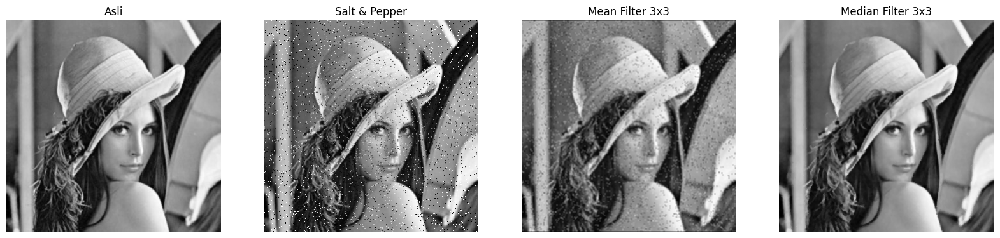

In [ ]:
# a. Tambahkan noise salt & pepper ke citra grayscale
img = cv.imread("/content/drive/MyDrive/Polinema/Semester 5/PCVK/Images/lena.jpg")
img_gray = cv.cvtColor(img, cv.COLOR_BGR2GRAY)

def salt_pepper(image, jumlah=0.05):
    noisy = image.copy()
    r = np.random.random(image.shape)
    noisy[r < jumlah/2] = 0                        # pepper (hitam)
    noisy[(r >= jumlah/2) & (r < jumlah)] = 255    # salt (putih)
    return noisy

noisy = salt_pepper(img_gray, 0.05)   # 5% piksel rusak

# b. Mean filter 3x3 (pakai fungsi konvolusi buatan sendiri) & Median filter 3x3
kernel_mean = np.ones((3,3)) / 9
mean_hasil = u8(convolution2d(noisy, kernel_mean, 1, 1))
median_hasil = cv.medianBlur(noisy, 3)

show_side_by_side([img_gray, noisy, mean_hasil, median_hasil],
                  ["Asli", "Salt & Pepper", "Mean Filter 3x3", "Median Filter 3x3"], figsize=(20,5))

### c. Analisis: mengapa Median Filter lebih bersih?
- Noise salt & pepper adalah **outlier** (0 atau 255), sangat berbeda dari piksel tetangganya.
- **Mean** menghitung rata-rata, jadi 1 piksel putih (255) di dalam jendela 3x3 ikut menaikkan hasil. Noise tidak hilang, hanya **menyebar** menjadi bercak abu-abu dan tepi ikut blur.
- **Median** mengurutkan nilai, sehingga outlier 0 dan 255 selalu berada di **ujung** urutan dan **tidak pernah terpilih** sebagai nilai tengah (selama noise < separuh jendela). Noise hilang total dan tepi tetap tajam.


# Tugas 2 – Ukuran Kernel Terbaik untuk Sharpening
Langkah: (a) buat kernel penajaman 3x3 dan 5x5, (b) terapkan pada citra yang sedikit buram, (c) evaluasi **kejelasan tepi** vs **noise/distorsi**.

Kedua kernel dibuat agar jumlah elemennya = 1 (kecerahan tetap):
- 3x3 : kernel sharpen standar modul.
- 5x5 : cincin luar -1, cincin dalam 2, pusat 8, lalu dibagi 8.

Jumlah kernel: 1 1.0


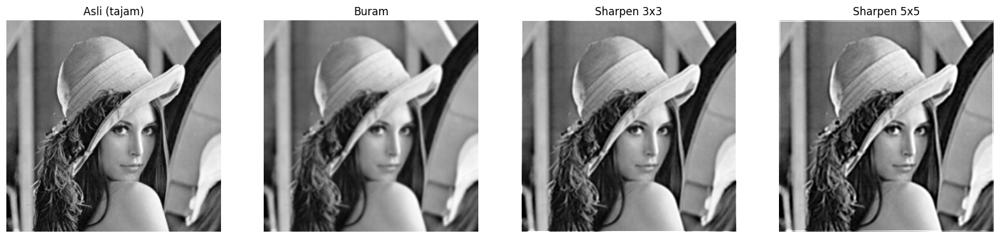

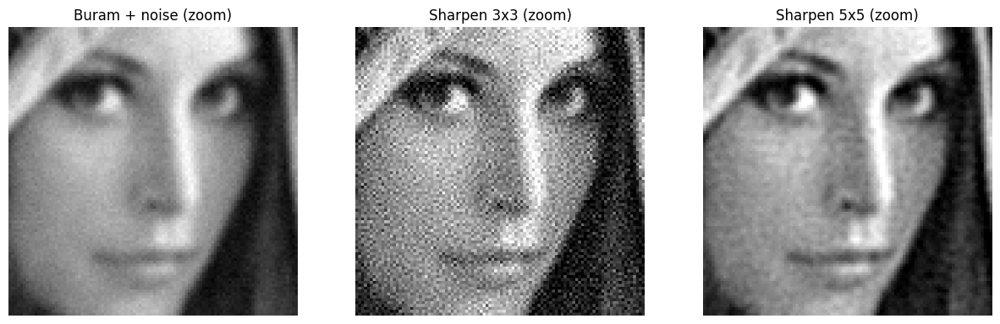

In [ ]:
# a. Kernel penajaman
sharp_3x3 = np.array([[ 0,-1, 0],
                      [-1, 5,-1],
                      [ 0,-1, 0]])

sharp_5x5 = np.array([[-1,-1,-1,-1,-1],
                      [-1, 2, 2, 2,-1],
                      [-1, 2, 8, 2,-1],
                      [-1, 2, 2, 2,-1],
                      [-1,-1,-1,-1,-1]]) / 8
print("Jumlah kernel:", sharp_3x3.sum(), sharp_5x5.sum())

# b. Citra sedikit buram + versi berderau
buram = cv.GaussianBlur(img_gray, (5,5), 1.5)
buram_noise = u8(buram + np.random.normal(0, 5, buram.shape))

hasil_3 = filter_citra(buram, sharp_3x3)
hasil_5 = filter_citra(buram, sharp_5x5)
hasil_3n = filter_citra(buram_noise, sharp_3x3)
hasil_5n = filter_citra(buram_noise, sharp_5x5)

show_side_by_side([img_gray, buram, hasil_3, hasil_5],
                  ["Asli (tajam)", "Buram", "Sharpen 3x3", "Sharpen 5x5"], figsize=(20,5))

# Zoom bagian citra berderau agar noise terlihat
def zoom(a):
    return cv.resize(a[150:250, 150:250], None, fx=3, fy=3, interpolation=cv.INTER_NEAREST)

show_side_by_side([zoom(buram_noise), zoom(hasil_3n), zoom(hasil_5n)],
                  ["Buram + noise (zoom)", "Sharpen 3x3 (zoom)", "Sharpen 5x5 (zoom)"])

### c. Evaluasi


| Aspek | 3x3 | 5x5 |
|---|---|---|
| Kejelasan tepi | Tepi halus/tipis jelas, hasil paling tajam | Tepi tampak lebih lembut, tekstur menengah ikut menguat |
| Noise | Noise **diperkuat paling banyak** (kernel 3x3 ini sekitar 5x lipat) | Noise lebih sedikit diperkuat karena lebih banyak piksel dilibatkan |
| Distorsi | Halo tipis di sekitar tepi | Halo lebih lebar, tekstur bisa tampak kasar |
| Komputasi | 9 perkalian/piksel | 25 perkalian/piksel (lebih berat) |

**Kesimpulan:** untuk penggunaan sehari-hari pada foto yang cukup bersih, **kernel 3x3 paling optimal** (tajam, cepat, distorsi kecil). Jika foto berderau, lakukan denoise dulu (median/bilateral) lalu sharpen 3x3, atau gunakan 5x5 yang lebih tenang terhadap noise.


# Tugas 3 – Filter Kartun Sederhana
Fungsi `kartun(image)` menggabungkan:
1. **Bilateral Filter** → warna menjadi rata (area warna halus, tepi tetap).
2. **Adaptive Thresholding** (atau Canny) → deteksi garis tepi. Hasilnya mask: garis = 0, selain itu = 255.
3. **Penggabungan** dengan operasi logika (`bitwise_and`) → warna dikali mask sehingga garis menjadi hitam.

Alur: `gambar → (bilateral) warna rata` dan `gambar → (gray → median blur → adaptive threshold) garis` → keduanya digabung.

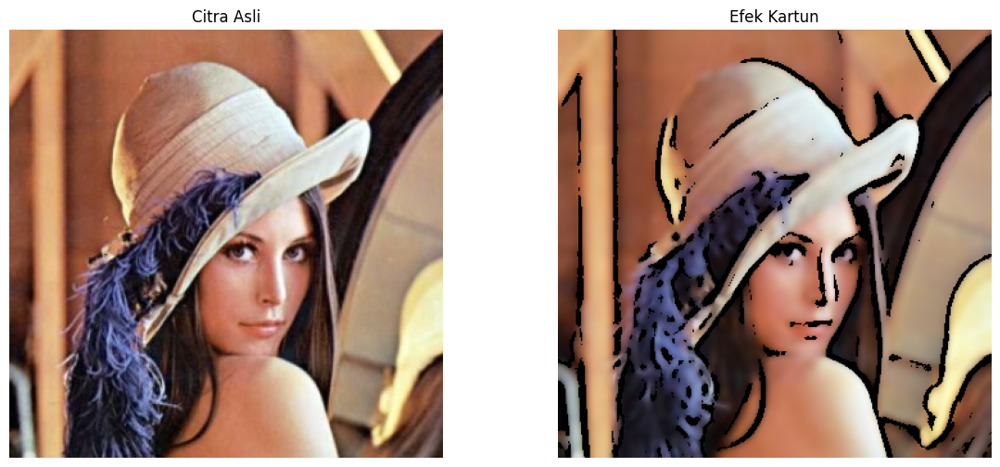

In [ ]:
def kartun(image):
    # 1. Penghalusan warna dengan Bilateral Filter
    warna = cv.bilateralFilter(image, d=9, sigmaColor=200, sigmaSpace=200)

    # 2. Deteksi garis tepi dengan Adaptive Thresholding
    gray = cv.cvtColor(image, cv.COLOR_BGR2GRAY)
    gray = cv.medianBlur(gray, 7)
    garis = cv.adaptiveThreshold(gray, 255, cv.ADAPTIVE_THRESH_MEAN_C,
                                 cv.THRESH_BINARY, 9, 9)

    # 3. Gabungkan warna + garis dengan operasi logika AND
    return cv.bitwise_and(warna, warna, mask=garis)

# b. Tampilkan citra asli dan hasil kartun bersebelahan
hasil_kartun = kartun(img)
show_side_by_side([img, hasil_kartun], ["Citra Asli", "Efek Kartun"], figsize=(14,6))

### (Opsional) Versi Canny + perkalian piksel
Alternatif deteksi tepi memakai **Canny** dan penggabungan dengan **perkalian piksel**. Canny menghasilkan garis putih (255), jadi di-invert agar garis = 0, lalu mask dinormalisasi ke 0–1 dan dikalikan ke citra warna.

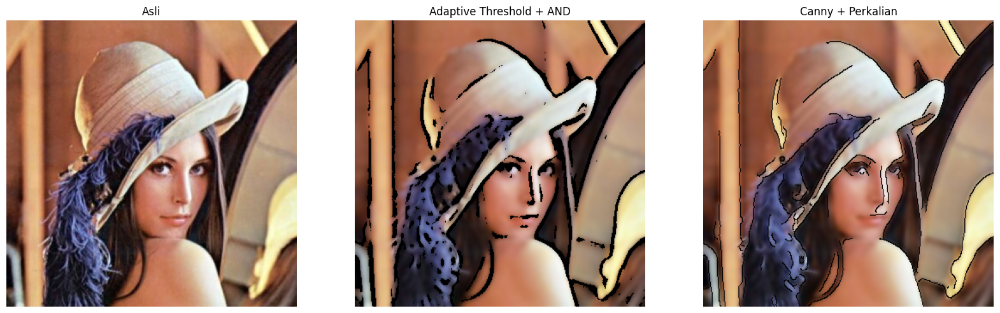

In [ ]:
def kartun_canny(image):
    warna = cv.bilateralFilter(image, d=9, sigmaColor=200, sigmaSpace=200)
    gray = cv.medianBlur(cv.cvtColor(image, cv.COLOR_BGR2GRAY), 7)
    garis = cv.Canny(gray, 100, 200)
    mask = cv.bitwise_not(garis) / 255.0          # garis = 0, area = 1
    return (warna * mask[:, :, None]).astype(np.uint8)

show_side_by_side([img, kartun(img), kartun_canny(img)],
                  ["Asli", "Adaptive Threshold + AND", "Canny + Perkalian"], figsize=(20,6))